# **I. IMPORTING THE NECESSARY LIBRARIES**

In [180]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, precision_recall_curve, auc

****

# **II. LOADING THE DATAFRAME**

In [181]:
# Initialize the original dataframe
df = pd.read_csv("/kaggle/input/datasets/margielynatienza/music-genre/music_genre.csv")

if df is not None: #Checks if the dataframe is loaded
    print("Loaded: Music Genre") 
    print(f"Rows: {len(df)} || Columns: {len(df.columns)}")

Loaded: Music Genre
Rows: 50005 || Columns: 18


****

# **III. ANALYZING THE ORIGINAL DATAFRAME**

In [182]:
df #check original dataset

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,obtained_date,valence,music_genre
0,32894.0,Röyksopp,Röyksopp's Night Out,27.0,0.00468,0.652,-1.0,0.941,0.79200,A#,0.115,-5.201,Minor,0.0748,100.889,4-Apr,0.759,Electronic
1,46652.0,Thievery Corporation,The Shining Path,31.0,0.01270,0.622,218293.0,0.890,0.95000,D,0.124,-7.043,Minor,0.0300,115.00200000000001,4-Apr,0.531,Electronic
2,30097.0,Dillon Francis,Hurricane,28.0,0.00306,0.620,215613.0,0.755,0.01180,G#,0.534,-4.617,Major,0.0345,127.994,4-Apr,0.333,Electronic
3,62177.0,Dubloadz,Nitro,34.0,0.02540,0.774,166875.0,0.700,0.00253,C#,0.157,-4.498,Major,0.2390,128.014,4-Apr,0.270,Electronic
4,24907.0,What So Not,Divide & Conquer,32.0,0.00465,0.638,222369.0,0.587,0.90900,F#,0.157,-6.266,Major,0.0413,145.036,4-Apr,0.323,Electronic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50000,58878.0,BEXEY,GO GETTA,59.0,0.03340,0.913,-1.0,0.574,0.00000,C#,0.119,-7.022,Major,0.2980,98.02799999999999,4-Apr,0.330,Hip-Hop
50001,43557.0,Roy Woods,Drama (feat. Drake),72.0,0.15700,0.709,251860.0,0.362,0.00000,B,0.109,-9.814,Major,0.0550,122.04299999999999,4-Apr,0.113,Hip-Hop
50002,39767.0,Berner,Lovin' Me (feat. Smiggz),51.0,0.00597,0.693,189483.0,0.763,0.00000,D,0.143,-5.443,Major,0.1460,131.079,4-Apr,0.395,Hip-Hop
50003,57944.0,The-Dream,Shawty Is Da Shit,65.0,0.08310,0.782,262773.0,0.472,0.00000,G,0.106,-5.016,Minor,0.0441,75.88600000000001,4-Apr,0.354,Hip-Hop


In [183]:
df.columns #print all column names

Index(['instance_id', 'artist_name', 'track_name', 'popularity',
       'acousticness', 'danceability', 'duration_ms', 'energy',
       'instrumentalness', 'key', 'liveness', 'loudness', 'mode',
       'speechiness', 'tempo', 'obtained_date', 'valence', 'music_genre'],
      dtype='object')

In [184]:
df.info() #print summary of information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50005 entries, 0 to 50004
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   instance_id       50000 non-null  float64
 1   artist_name       50000 non-null  object 
 2   track_name        50000 non-null  object 
 3   popularity        50000 non-null  float64
 4   acousticness      50000 non-null  float64
 5   danceability      50000 non-null  float64
 6   duration_ms       50000 non-null  float64
 7   energy            50000 non-null  float64
 8   instrumentalness  50000 non-null  float64
 9   key               50000 non-null  object 
 10  liveness          50000 non-null  float64
 11  loudness          50000 non-null  float64
 12  mode              50000 non-null  object 
 13  speechiness       50000 non-null  float64
 14  tempo             50000 non-null  object 
 15  obtained_date     50000 non-null  object 
 16  valence           50000 non-null  float6

In [185]:
df.describe() #generates description

,instance_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,valence
count,50000.000000,50000.000000,50000.000000,50000.000000,5.000000e+04,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,55888.396360,44.220420,0.306383,0.558241,2.212526e+05,0.599755,0.181601,0.193896,-9.133761,0.093586,0.456264
std,20725.256253,15.542008,0.341340,0.178632,1.286720e+05,0.264559,0.325409,0.161637,6.162990,0.101373,0.247119
min,20002.000000,0.000000,0.000000,0.059600,-1.000000e+00,0.000792,0.000000,0.009670,-47.046000,0.022300,0.000000
25%,37973.500000,34.000000,0.020000,0.442000,1.748000e+05,0.433000,0.000000,0.096900,-10.860000,0.036100,0.257000
50%,55913.500000,45.000000,0.144000,0.568000,2.192810e+05,0.643000,0.000158,0.126000,-7.276500,0.048900,0.448000
75%,73863.250000,56.000000,0.552000,0.687000,2.686122e+05,0.815000,0.155000,0.244000,-5.173000,0.098525,0.648000
max,91759.000000,99.000000,0.996000,0.986000,4.830606e+06,0.999000,0.996000,1.000000,3.744000,0.942000,0.992000


In [186]:
df.shape #prints number of rows and columns

(50005, 18)

In [187]:
df.head(5) #prints the first 5 rows

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,obtained_date,valence,music_genre
0,32894.0,Röyksopp,Röyksopp's Night Out,27.0,0.00468,0.652,-1.0,0.941,0.79200,A#,0.115,-5.201,Minor,0.0748,100.889,4-Apr,0.759,Electronic
1,46652.0,Thievery Corporation,The Shining Path,31.0,0.01270,0.622,218293.0,0.890,0.95000,D,0.124,-7.043,Minor,0.0300,115.00200000000001,4-Apr,0.531,Electronic
2,30097.0,Dillon Francis,Hurricane,28.0,0.00306,0.620,215613.0,0.755,0.01180,G#,0.534,-4.617,Major,0.0345,127.994,4-Apr,0.333,Electronic
3,62177.0,Dubloadz,Nitro,34.0,0.02540,0.774,166875.0,0.700,0.00253,C#,0.157,-4.498,Major,0.2390,128.014,4-Apr,0.270,Electronic
4,24907.0,What So Not,Divide & Conquer,32.0,0.00465,0.638,222369.0,0.587,0.90900,F#,0.157,-6.266,Major,0.0413,145.036,4-Apr,0.323,Electronic


In [188]:
df.tail(5) #prints the last 5 rows

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,obtained_date,valence,music_genre
50000,58878.0,BEXEY,GO GETTA,59.0,0.03340,0.913,-1.0,0.574,0.0,C#,0.119,-7.022,Major,0.2980,98.02799999999999,4-Apr,0.330,Hip-Hop
50001,43557.0,Roy Woods,Drama (feat. Drake),72.0,0.15700,0.709,251860.0,0.362,0.0,B,0.109,-9.814,Major,0.0550,122.04299999999999,4-Apr,0.113,Hip-Hop
50002,39767.0,Berner,Lovin' Me (feat. Smiggz),51.0,0.00597,0.693,189483.0,0.763,0.0,D,0.143,-5.443,Major,0.1460,131.079,4-Apr,0.395,Hip-Hop
50003,57944.0,The-Dream,Shawty Is Da Shit,65.0,0.08310,0.782,262773.0,0.472,0.0,G,0.106,-5.016,Minor,0.0441,75.88600000000001,4-Apr,0.354,Hip-Hop
50004,63470.0,Naughty By Nature,Hip Hop Hooray,67.0,0.10200,0.862,267267.0,0.642,0.0,F#,0.272,-13.652,Minor,0.1010,99.20100000000001,4-Apr,0.765,Hip-Hop


****

# **IV. DUPLICATING THE DATAFRAME**

In [189]:
data = df.copy() #independent copy of original dataset for data manipulation

In [190]:
data #print the duplicated dataset

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,obtained_date,valence,music_genre
0,32894.0,Röyksopp,Röyksopp's Night Out,27.0,0.00468,0.652,-1.0,0.941,0.79200,A#,0.115,-5.201,Minor,0.0748,100.889,4-Apr,0.759,Electronic
1,46652.0,Thievery Corporation,The Shining Path,31.0,0.01270,0.622,218293.0,0.890,0.95000,D,0.124,-7.043,Minor,0.0300,115.00200000000001,4-Apr,0.531,Electronic
2,30097.0,Dillon Francis,Hurricane,28.0,0.00306,0.620,215613.0,0.755,0.01180,G#,0.534,-4.617,Major,0.0345,127.994,4-Apr,0.333,Electronic
3,62177.0,Dubloadz,Nitro,34.0,0.02540,0.774,166875.0,0.700,0.00253,C#,0.157,-4.498,Major,0.2390,128.014,4-Apr,0.270,Electronic
4,24907.0,What So Not,Divide & Conquer,32.0,0.00465,0.638,222369.0,0.587,0.90900,F#,0.157,-6.266,Major,0.0413,145.036,4-Apr,0.323,Electronic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50000,58878.0,BEXEY,GO GETTA,59.0,0.03340,0.913,-1.0,0.574,0.00000,C#,0.119,-7.022,Major,0.2980,98.02799999999999,4-Apr,0.330,Hip-Hop
50001,43557.0,Roy Woods,Drama (feat. Drake),72.0,0.15700,0.709,251860.0,0.362,0.00000,B,0.109,-9.814,Major,0.0550,122.04299999999999,4-Apr,0.113,Hip-Hop
50002,39767.0,Berner,Lovin' Me (feat. Smiggz),51.0,0.00597,0.693,189483.0,0.763,0.00000,D,0.143,-5.443,Major,0.1460,131.079,4-Apr,0.395,Hip-Hop
50003,57944.0,The-Dream,Shawty Is Da Shit,65.0,0.08310,0.782,262773.0,0.472,0.00000,G,0.106,-5.016,Minor,0.0441,75.88600000000001,4-Apr,0.354,Hip-Hop


# **V. DATA CLEANING**

## **V.I. DUPLICATING THE DATA SET**

In [191]:
data.duplicated() #check for duplicate records

0        False
1        False
2        False
3        False
4        False
         ...  
50000    False
50001    False
50002    False
50003    False
50004    False
Length: 50005, dtype: bool

## **V.II. ERASING DUPLICATE ROWS**

In [192]:
data.duplicated().sum() #gets the amount of duplicated rows

np.int64(4)

In [193]:
data = data.drop_duplicates() #deletes all the duplicated rows

In [194]:
data #check the dataset for differences

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,obtained_date,valence,music_genre
0,32894.0,Röyksopp,Röyksopp's Night Out,27.0,0.00468,0.652,-1.0,0.941,0.79200,A#,0.115,-5.201,Minor,0.0748,100.889,4-Apr,0.759,Electronic
1,46652.0,Thievery Corporation,The Shining Path,31.0,0.01270,0.622,218293.0,0.890,0.95000,D,0.124,-7.043,Minor,0.0300,115.00200000000001,4-Apr,0.531,Electronic
2,30097.0,Dillon Francis,Hurricane,28.0,0.00306,0.620,215613.0,0.755,0.01180,G#,0.534,-4.617,Major,0.0345,127.994,4-Apr,0.333,Electronic
3,62177.0,Dubloadz,Nitro,34.0,0.02540,0.774,166875.0,0.700,0.00253,C#,0.157,-4.498,Major,0.2390,128.014,4-Apr,0.270,Electronic
4,24907.0,What So Not,Divide & Conquer,32.0,0.00465,0.638,222369.0,0.587,0.90900,F#,0.157,-6.266,Major,0.0413,145.036,4-Apr,0.323,Electronic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50000,58878.0,BEXEY,GO GETTA,59.0,0.03340,0.913,-1.0,0.574,0.00000,C#,0.119,-7.022,Major,0.2980,98.02799999999999,4-Apr,0.330,Hip-Hop
50001,43557.0,Roy Woods,Drama (feat. Drake),72.0,0.15700,0.709,251860.0,0.362,0.00000,B,0.109,-9.814,Major,0.0550,122.04299999999999,4-Apr,0.113,Hip-Hop
50002,39767.0,Berner,Lovin' Me (feat. Smiggz),51.0,0.00597,0.693,189483.0,0.763,0.00000,D,0.143,-5.443,Major,0.1460,131.079,4-Apr,0.395,Hip-Hop
50003,57944.0,The-Dream,Shawty Is Da Shit,65.0,0.08310,0.782,262773.0,0.472,0.00000,G,0.106,-5.016,Minor,0.0441,75.88600000000001,4-Apr,0.354,Hip-Hop


In [195]:
data.duplicated().sum() #confirming no more duplicates

np.int64(0)

## **V.III. CHECKING FOR MISSING VALUES**

In [196]:
data.count() #checks name of each column and amount of non-missing entries

instance_id         50000
artist_name         50000
track_name          50000
popularity          50000
acousticness        50000
danceability        50000
duration_ms         50000
energy              50000
instrumentalness    50000
key                 50000
liveness            50000
loudness            50000
mode                50000
speechiness         50000
tempo               50000
obtained_date       50000
valence             50000
music_genre         50000
dtype: int64

In [197]:
data.isnull().sum() #checks number of missing values in each column

instance_id         1
artist_name         1
track_name          1
popularity          1
acousticness        1
danceability        1
duration_ms         1
energy              1
instrumentalness    1
key                 1
liveness            1
loudness            1
mode                1
speechiness         1
tempo               1
obtained_date       1
valence             1
music_genre         1
dtype: int64

In [198]:
data["tempo"].value_counts() # checks for missing placeholders

tempo
?                     4980
140.007                 17
120.0                   17
100.00299999999999      16
100.00200000000001      15
                      ... 
172.97400000000002       1
184.916                  1
146.97299999999998       1
100.05                   1
113.98200000000001       1
Name: count, Length: 29394, dtype: int64

In [199]:
data = data.replace("?", np.nan) # removes the unknown placeholder:'?' 

In [200]:
data["tempo"].value_counts() # checks for missing placeholders

tempo
140.007               17
120.0                 17
100.00299999999999    16
100.014               15
100.00200000000001    15
                      ..
145.658                1
88.21                  1
118.885                1
172.97400000000002     1
137.046                1
Name: count, Length: 29393, dtype: int64

## **V.IV. REMOVE IRRELEVANT COLUMNS**

In [201]:
irrelevant_columns = data[["instance_id", "artist_name", "track_name", "obtained_date"]] #create array of columns to remove

#loop to remove columns
for i in irrelevant_columns:
    data = data.drop(i, axis = "columns")

In [202]:
data #check data to see

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,music_genre
0,27.0,0.00468,0.652,-1.0,0.941,0.79200,A#,0.115,-5.201,Minor,0.0748,100.889,0.759,Electronic
1,31.0,0.01270,0.622,218293.0,0.890,0.95000,D,0.124,-7.043,Minor,0.0300,115.00200000000001,0.531,Electronic
2,28.0,0.00306,0.620,215613.0,0.755,0.01180,G#,0.534,-4.617,Major,0.0345,127.994,0.333,Electronic
3,34.0,0.02540,0.774,166875.0,0.700,0.00253,C#,0.157,-4.498,Major,0.2390,128.014,0.270,Electronic
4,32.0,0.00465,0.638,222369.0,0.587,0.90900,F#,0.157,-6.266,Major,0.0413,145.036,0.323,Electronic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50000,59.0,0.03340,0.913,-1.0,0.574,0.00000,C#,0.119,-7.022,Major,0.2980,98.02799999999999,0.330,Hip-Hop
50001,72.0,0.15700,0.709,251860.0,0.362,0.00000,B,0.109,-9.814,Major,0.0550,122.04299999999999,0.113,Hip-Hop
50002,51.0,0.00597,0.693,189483.0,0.763,0.00000,D,0.143,-5.443,Major,0.1460,131.079,0.395,Hip-Hop
50003,65.0,0.08310,0.782,262773.0,0.472,0.00000,G,0.106,-5.016,Minor,0.0441,75.88600000000001,0.354,Hip-Hop


In [203]:
data.shape # check shape of data

(50001, 14)

## **V.V. CHECKING IMPOSSIBLE VALUES**

In [204]:
data.loc[data["duration_ms"] <= 0, "duration_ms"] = np.nan # replace all the values less than or equal to 0 in the 'duration_ms' column with NaN

## **V.VI. FIXING INCONSISTENT FORMATS**

In [205]:
data["tempo"] = pd.to_numeric(data["tempo"]) # converts string to float

In [206]:
rounded_columns = data[["acousticness", "danceability", "duration_ms", "energy", "instrumentalness", "liveness", "speechiness", "tempo"]] #create array of columns

#loop to round values in columns
for i in rounded_columns:
    data[i] = data[i].round(3)

data.head()

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,music_genre
0,27.0,0.005,0.652,NaN,0.941,0.792,A#,0.115,-5.201,Minor,0.075,100.889,0.759,Electronic
1,31.0,0.013,0.622,218293.0,0.890,0.950,D,0.124,-7.043,Minor,0.030,115.002,0.531,Electronic
2,28.0,0.003,0.620,215613.0,0.755,0.012,G#,0.534,-4.617,Major,0.034,127.994,0.333,Electronic
3,34.0,0.025,0.774,166875.0,0.700,0.003,C#,0.157,-4.498,Major,0.239,128.014,0.270,Electronic
4,32.0,0.005,0.638,222369.0,0.587,0.909,F#,0.157,-6.266,Major,0.041,145.036,0.323,Electronic


## **V.VII. CHECKING INVALID LABELS**

In [207]:
data["music_genre"].isnull().sum() # check target label for missing entries

np.int64(1)

In [208]:
data = data.dropna(subset = ["music_genre"]) # drops all rows with missing values based on the target variable

In [209]:
data["music_genre"].isnull().sum() # confirm if there are no missing entries in the target variable

np.int64(0)

In [210]:
data["music_genre"].value_counts()

music_genre
Electronic     5000
Anime          5000
Jazz           5000
Alternative    5000
Country        5000
Rap            5000
Blues          5000
Rock           5000
Classical      5000
Hip-Hop        5000
Name: count, dtype: int64

In [211]:
le = LabelEncoder()

In [212]:
data["music_genre"].value_counts()

music_genre
Electronic     5000
Anime          5000
Jazz           5000
Alternative    5000
Country        5000
Rap            5000
Blues          5000
Rock           5000
Classical      5000
Hip-Hop        5000
Name: count, dtype: int64

In [213]:
data["music_genre"] = le.fit_transform(data["music_genre"])

/tmp/ipykernel_2290/1832562486.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["music_genre"] = le.fit_transform(data["music_genre"])


## **V.VII. RE-ANALYZING THE DATA**

In [214]:
data.shape # check shape of dataset post data cleaning

(50000, 14)

In [215]:
data # check dataset post data cleaning

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,music_genre
0,27.0,0.005,0.652,NaN,0.941,0.792,A#,0.115,-5.201,Minor,0.075,100.889,0.759,5
1,31.0,0.013,0.622,218293.0,0.890,0.950,D,0.124,-7.043,Minor,0.030,115.002,0.531,5
2,28.0,0.003,0.620,215613.0,0.755,0.012,G#,0.534,-4.617,Major,0.034,127.994,0.333,5
3,34.0,0.025,0.774,166875.0,0.700,0.003,C#,0.157,-4.498,Major,0.239,128.014,0.270,5
4,32.0,0.005,0.638,222369.0,0.587,0.909,F#,0.157,-6.266,Major,0.041,145.036,0.323,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50000,59.0,0.033,0.913,NaN,0.574,0.000,C#,0.119,-7.022,Major,0.298,98.028,0.330,6
50001,72.0,0.157,0.709,251860.0,0.362,0.000,B,0.109,-9.814,Major,0.055,122.043,0.113,6
50002,51.0,0.006,0.693,189483.0,0.763,0.000,D,0.143,-5.443,Major,0.146,131.079,0.395,6
50003,65.0,0.083,0.782,262773.0,0.472,0.000,G,0.106,-5.016,Minor,0.044,75.886,0.354,6


****

# **VI. DATA SPLITTING**

## **VI.I. FEATURE LABEL SEPARATION**

In [216]:
X = data.drop("music_genre", axis = "columns") #stores a version of the data without the target variable as 'X'

In [217]:
y = data["music_genre"] #stores the target variable as 'y'

In [218]:
X.head() #displays X's first 5 rows

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence
0,27.0,0.005,0.652,NaN,0.941,0.792,A#,0.115,-5.201,Minor,0.075,100.889,0.759
1,31.0,0.013,0.622,218293.0,0.890,0.950,D,0.124,-7.043,Minor,0.030,115.002,0.531
2,28.0,0.003,0.620,215613.0,0.755,0.012,G#,0.534,-4.617,Major,0.034,127.994,0.333
3,34.0,0.025,0.774,166875.0,0.700,0.003,C#,0.157,-4.498,Major,0.239,128.014,0.270
4,32.0,0.005,0.638,222369.0,0.587,0.909,F#,0.157,-6.266,Major,0.041,145.036,0.323


In [219]:
y.head() #displays y's first 5 rows

0    5
1    5
2    5
3    5
4    5
Name: music_genre, dtype: int64

## **VI.II. TRAIN TEST SPLIT**

In [220]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #splits X and Y into training and testing data

## **VI.III. ANALYZING SPLITTED RESULTS**

In [221]:
data.shape #check the shape of the entire dataset

(50000, 14)

In [222]:
X_train.shape #check the shape of the training features

(40000, 13)

In [223]:
X_test.shape #check the shape of the testing features

(10000, 13)

In [224]:
y_train.shape #check the shape of the training target variable

(40000,)

In [225]:
y_test.shape #check the shape of the testing target variable

(10000,)

In [226]:
print("Training Music Qualities:", len(X_train)) #check amount of rows of training features
print("Training Music Genres:", len(y_train)) #check amount of rows of the training target variable

print("Test Music Qualities:", len(X_test)) #check amount of rows of testing features
print("Test Music Genres:", len(y_test)) #check amount of rows of the testing target variable

Training Music Qualities: 40000
Training Music Genres: 40000
Test Music Qualities: 10000
Test Music Genres: 10000


****

# **VII. DATA PREPROCESSING**

In [227]:
# create copies so original training data remain unchanged
X_train_prepared = X_train.copy()
X_test_prepared = X_test.copy()

## **VII.I. HANDLING MISSING VALUES**

In [228]:
X_train_prepared.isnull().sum() #check missing values in training data

popularity             0
acousticness           0
danceability           0
duration_ms         3950
energy                 0
instrumentalness       0
key                    0
liveness               0
loudness               0
mode                   0
speechiness            0
tempo               3969
valence                0
dtype: int64

In [229]:
X_test_prepared.isnull().sum() #check missing values in testing data

popularity             0
acousticness           0
danceability           0
duration_ms          989
energy                 0
instrumentalness       0
key                    0
liveness               0
loudness               0
mode                   0
speechiness            0
tempo               1011
valence                0
dtype: int64

In [230]:
# Mean Imputation on 'duration_ms' column
duration_mean = X_train_prepared["duration_ms"].mean()
X_train_prepared["duration_ms"] = X_train_prepared["duration_ms"].fillna(duration_mean) 
X_test_prepared["duration_ms"] = X_test_prepared["duration_ms"].fillna(duration_mean)

In [231]:
# Mean Imputation on 'tempo' column
tempo_mean = X_train_prepared["tempo"].mean()
X_train_prepared["tempo"] = X_train_prepared["tempo"].fillna(tempo_mean) 
X_test_prepared["tempo"] = X_test_prepared["tempo"].fillna(tempo_mean)

In [232]:
X_train_prepared.isnull().sum() # confirm filled values in training data

popularity          0
acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
tempo               0
valence             0
dtype: int64

In [233]:
X_test_prepared.isnull().sum() # confirm filled values in testing data

popularity          0
acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
tempo               0
valence             0
dtype: int64

## **VII.II. FEATURE SCALING**

In [234]:
numeric_columns = ["popularity", "acousticness", "danceability", "duration_ms", "energy", "instrumentalness","liveness", "loudness", "speechiness", "tempo", "valence"] # All the columns you want to scale

In [235]:
scaler = StandardScaler() # create scaler object

In [236]:
X_train_prepared[numeric_columns] = scaler.fit_transform(X_train_prepared[numeric_columns]) #fit scaler on training data & transform training data

In [237]:
X_test_prepared[numeric_columns] = scaler.transform(X_test_prepared[numeric_columns]) # apply same scaling rule on testing data

In [238]:
X_train_prepared.head() # check the post-scaled training data

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence
39092,0.500021,-0.852800,-0.296355,0.295552,0.331269,-0.492182,D#,-0.032443,0.643809,Minor,-0.636106,-4.898185e-16,-1.650744
30898,-0.789083,1.307540,-1.419391,0.000000,-1.097589,-0.559709,G#,-0.488697,-0.375625,Major,-0.636106,5.286500e-01,-0.436246
45283,1.337938,0.306407,1.279247,-0.328219,-0.050516,-0.559709,A#,-0.470200,-0.079775,Major,-0.230327,-4.898185e-16,0.504818
16403,-0.015621,-0.896709,-0.782445,0.000000,1.385902,-0.541292,G,0.171021,1.051776,Minor,1.184954,1.897750e+00,0.512896
13658,0.242200,-0.571780,-0.815969,0.871248,0.217867,-0.559709,F#,-0.272901,-0.426500,Major,-0.042282,3.190851e-01,1.155081


## **VII.III. CATEGORICAL ENCODING**

In [239]:
# converts intro binary coding for training data
X_train_prepared["mode"] = X_train_prepared["mode"].replace({
    "Major": 1,
    "Minor": 0
})

/tmp/ipykernel_2290/3864909712.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train_prepared["mode"] = X_train_prepared["mode"].replace({


In [240]:
# converts intro binary coding for testing data
X_test_prepared["mode"] = X_test_prepared["mode"].replace({
    "Major": 1,
    "Minor": 0
})

/tmp/ipykernel_2290/2473687305.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test_prepared["mode"] = X_test_prepared["mode"].replace({


In [241]:
# converts column into numerical columns using one-hot encoding
X_train_prepared = pd.get_dummies(X_train_prepared, columns = ["key"], dtype = int)
X_test_prepared = pd.get_dummies(X_test_prepared, columns = ["key"], dtype = int)

In [242]:
X_train_prepared.mean() # get the mean of each column

popularity         -1.179501e-16
acousticness        1.207923e-16
danceability        2.810197e-16
duration_ms         3.463896e-17
energy             -5.684342e-18
instrumentalness    6.750156e-17
liveness            6.306067e-17
loudness            3.659295e-16
mode                6.409500e-01
speechiness        -1.477929e-16
tempo              -3.321787e-17
valence             1.030287e-16
key_A               9.727500e-02
key_A#              6.755000e-02
key_B               7.615000e-02
key_C               1.108000e-01
key_C#              1.082250e-01
key_D               1.049750e-01
key_D#              3.192500e-02
key_E               7.435000e-02
key_F               8.525000e-02
key_F#              6.247500e-02
key_G               1.151750e-01
key_G#              6.585000e-02
dtype: float64

In [243]:
X_train_prepared.std() # get the standard deviation of each column

popularity          1.000013
acousticness        1.000013
danceability        1.000013
duration_ms         1.000013
energy              1.000013
instrumentalness    1.000013
liveness            1.000013
loudness            1.000013
mode                0.479728
speechiness         1.000013
tempo               1.000013
valence             1.000013
key_A               0.296336
key_A#              0.250975
key_B               0.265241
key_C               0.313888
key_C#              0.310668
key_D               0.306525
key_D#              0.175803
key_E               0.262343
key_F               0.279257
key_F#              0.242019
key_G               0.319237
key_G#              0.248023
dtype: float64

In [244]:
X_test_prepared.head() # check the post-scaled testing data

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,mode,speechiness,...,key_B,key_C,key_C#,key_D,key_D#,key_E,key_F,key_F#,key_G,key_G#
33558,-1.240269,-0.873291,-0.156674,-0.366622,1.121299,-0.550501,-0.685996,0.592772,1,0.432777,...,0,0,0,0,0,0,0,0,1,0
9427,-1.949276,-0.896709,-1.005935,0.367149,0.932296,1.730074,-0.778480,0.601521,0,-0.319400,...,0,0,0,0,0,0,0,0,0,1
199,-0.531262,-0.823527,1.715052,0.268825,0.191407,-0.559709,-0.568850,0.181888,0,0.076483,...,0,0,0,0,0,0,0,0,0,0
12452,0.500021,1.702724,0.469097,-0.562514,-1.740196,-0.559709,0.886230,-0.911913,1,-0.616312,...,0,1,0,0,0,0,0,0,0,0
39494,1.273483,-0.879146,0.318242,-0.074931,-0.424740,-0.550501,-0.581181,-0.152523,0,-0.655900,...,1,0,0,0,0,0,0,0,0,0


## **VII.IV. HANDLING IMBALANCE**

In [245]:
data["music_genre"].value_counts(normalize=True)


music_genre
5    0.1
1    0.1
7    0.1
0    0.1
4    0.1
8    0.1
2    0.1
9    0.1
3    0.1
6    0.1
Name: proportion, dtype: float64

<Axes: ylabel='count'>

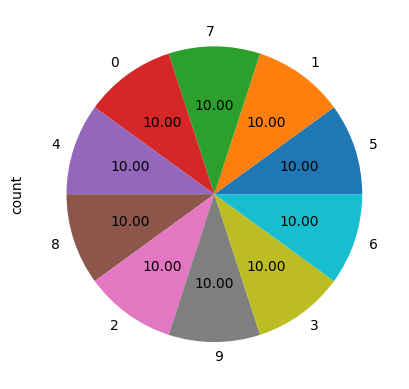

In [246]:
data["music_genre"].value_counts().plot.pie(autopct="%.2f")

****

# **VIII. MODEL TRAINING**

## **VIII.I. MODEL SELECTION**

In [247]:
model = LogisticRegression(class_weight='balanced') # create Logistic Regression model object and balances the data

In [248]:
model # display selected model

LogisticRegression(class_weight='balanced')

In [249]:
X_train_prepared.head() # training features

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,mode,speechiness,...,key_B,key_C,key_C#,key_D,key_D#,key_E,key_F,key_F#,key_G,key_G#
39092,0.500021,-0.852800,-0.296355,0.295552,0.331269,-0.492182,-0.032443,0.643809,0,-0.636106,...,0,0,0,0,1,0,0,0,0,0
30898,-0.789083,1.307540,-1.419391,0.000000,-1.097589,-0.559709,-0.488697,-0.375625,1,-0.636106,...,0,0,0,0,0,0,0,0,0,1
45283,1.337938,0.306407,1.279247,-0.328219,-0.050516,-0.559709,-0.470200,-0.079775,1,-0.230327,...,0,0,0,0,0,0,0,0,0,0
16403,-0.015621,-0.896709,-0.782445,0.000000,1.385902,-0.541292,0.171021,1.051776,0,1.184954,...,0,0,0,0,0,0,0,0,1,0
13658,0.242200,-0.571780,-0.815969,0.871248,0.217867,-0.559709,-0.272901,-0.426500,1,-0.042282,...,0,0,0,0,0,0,0,1,0,0


In [250]:
y_train.head() # training label

39092    9
30898    2
45283    6
16403    0
13658    7
Name: music_genre, dtype: int64

## **VIII.II. TRAINING THE MODEL**

In [251]:
model.fit(X_train_prepared, y_train) # train the Logistic Regression model

LogisticRegression(class_weight='balanced')

****

# **IX. MODEL EVALUATION**

## **IX.I. MODEL TESTING**

In [252]:
y_pred = model.predict(X_test_prepared) # predict target variable for testing data

In [253]:
y_pred[:10] # display predicted values

array([1, 1, 5, 4, 9, 3, 3, 6, 9, 0])

In [254]:
y_pred.shape # display shape of predicted values

(10000,)

## **IX.II. COMPARING THE RESULTS**

In [255]:
# comapring the actual values and predicted values
comparison = pd.DataFrame({
    "Original row": y_test.index,
    "Actual music genre": y_test.to_numpy(),
    "Predicted music genre": y_pred
})

display(comparison.head(10)) # display the comparison, showing 10 rows, and rounded off to two decimal points

,Original row,Actual music genre,Predicted music genre
0,33558,2,1
1,9427,1,1
2,199,5,5
3,12452,7,4
4,39494,9,9
5,42729,3,3
6,10827,7,3
7,49503,6,6
8,4144,5,9
9,36963,9,0


## **IX.III. PERFORMANCE EVALUATION METRICS**

In [256]:
# initialize all the performance evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average=None)
recall = recall_score(y_test, y_pred, average=None)
f1 = f1_score(y_test, y_pred, average=None)

In [257]:
precision_eval = pd.DataFrame({
    "Genre" : ["Electronic", "Anime", "Jazz", "Alternative", "Country", "Rap", "Blues", "Rock", "Classical", "Hip-Hop"],
    "Precision Score" : precision
})

precision_eval.round(2) # rounds off values into two decimal points

,Genre,Precision Score
0,Electronic,0.38
1,Anime,0.61
2,Jazz,0.53
3,Alternative,0.77
4,Country,0.44
5,Rap,0.58
6,Blues,0.46
7,Rock,0.48
8,Classical,0.48
9,Hip-Hop,0.52


In [258]:
recall_eval = pd.DataFrame({
    "Genre" : ["Electronic", "Anime", "Jazz", "Alternative", "Country", "Rap", "Blues", "Rock", "Classical", "Hip-Hop"],
    "Recall Score" : recall
})

recall_eval.round(2) # rounds off values into two decimal points

,Genre,Recall Score
0,Electronic,0.29
1,Anime,0.61
2,Jazz,0.49
3,Alternative,0.80
4,Country,0.58
5,Rap,0.59
6,Blues,0.49
7,Rock,0.41
8,Classical,0.39
9,Hip-Hop,0.64


In [259]:
f1_eval = pd.DataFrame({
    "Genre" : ["Electronic", "Anime", "Jazz", "Alternative", "Country", "Rap", "Blues", "Rock", "Classical", "Hip-Hop"],
    "F1 Score" : f1
})

f1_eval.round(2) # rounds off values into two decimal points

,Genre,F1 Score
0,Electronic,0.33
1,Anime,0.61
2,Jazz,0.51
3,Alternative,0.79
4,Country,0.50
5,Rap,0.59
6,Blues,0.48
7,Rock,0.45
8,Classical,0.43
9,Hip-Hop,0.57


In [260]:
# creates a table for evaluating each score
evaluation = pd.DataFrame({
    "Metric": ["Accuracy Score", "Precision Score", "Recall Score", "F1 Score"],
    "Average Score": [accuracy, precision.mean(), recall.mean(), f1.mean()]
})

evaluation.round(2) # rounds off values into two decimal points

,Metric,Average Score
0,Accuracy Score,0.53
1,Precision Score,0.53
2,Recall Score,0.53
3,F1 Score,0.52


****

# **X. VISUALIZATION**

## **X.I. CONFUSION MATRIX DISPLAY**

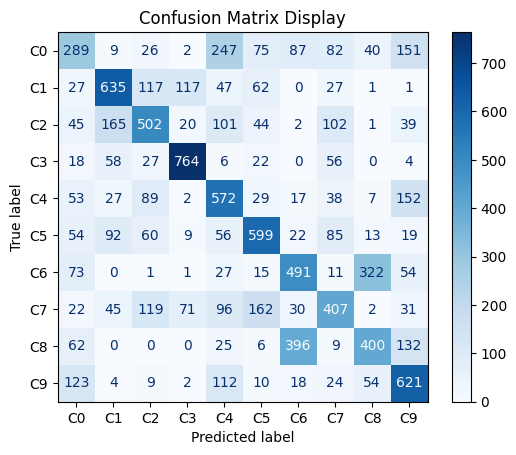

In [261]:
confusion = confusion_matrix(y_test, y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9'])
cm_display.plot(cmap=plt.cm.Blues)


plt.title('Confusion Matrix Display')
plt.show()

## **X.II. ROC CURVE**

In [262]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

ValueError: multiclass format is not supported

In [ ]:
plt.figure()
plt.plot(fpr, tpr, label='ROC Curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Water Potability')
plt.legend()
plt.show()

## **X.III. PRECISION-RECALL CURVE**

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_pred)
auc_score = auc(recall, precision)

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()